# Market overview & bức tranh khách hàng, hệ thống lead, SA · BI10 Round 3

> **Bước 2b/5 · Bối cảnh trước khi đánh giá shop** · bản đồ toàn bài: `README.md`
>
> **Câu hỏi của đề được trả lời ở đây:**
> - *What data are needed to understand shop performance and potential* – phần bối cảnh: thị trường, khách hàng, lead, nhân sự
> - Nối **Round 2 → Round 3** (đề yêu cầu một mạch xuyên suốt "from understanding customers to evaluating the shop's growth potential")
>
> **Đầu vào → đầu ra:** Round 2 (`CUSTOMER`, `CONTRACT`, `LEADS`) + Round 3 (`data_clean/`) → biểu đồ bối cảnh cho báo cáo
>
> **Đọc tiếp:** `03_Current_Actual.ipynb`

| Mục | Câu hỏi | Dữ liệu |
|---|---|---|
| A | Thị trường cho vay tiêu dùng lớn và tăng ra sao? | Round 2 `CONTRACT` (2009–06/2025), Round 3 `contract` (2025–09/2026) |
| B | Khách hàng là ai? | Round 2 `CUSTOMER` (1,0 triệu khách) + thu nhập, nghề nghiệp từ `CONTRACT` |
| C | Khách vay gì, vay bao nhiêu, trả nợ thế nào? | Round 2 `CONTRACT` |
| D | Hệ thống lead vận hành thế nào? | Round 2 `LEADS` (từ 2019), Round 3 `leads` (từ 31/12/2025) |
| E | Đội ngũ SA được phân bổ và tải việc ra sao? | Round 3 `emp_2_salesroom`, mã SA trong `leads` |

**Lưu ý dữ liệu:** Round 2 là **mẫu** khách hàng (12/2024–01/2025 bị lấy mẫu dày hơn) nên chỉ dùng để mô tả **cơ cấu**, không dùng số tuyệt đối để đo tăng trưởng gần đây. Dữ liệu không có giới tính, tuổi hay cấp bậc của SA, nên phần E dùng dữ liệu phân công và mã SA trong lead.

In [1]:
import duckdb, numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib.ticker as mtick, pathlib, seaborn as sns
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
R2 = pathlib.Path(r'D:/Thi/BI/BI10_ROUND02_DATASET/data'); CLEAN = pathlib.Path('data_clean')
con = duckdb.connect(); con.sql("SET preserve_insertion_order=false")
q = lambda s: con.sql(s).df()
r2 = lambda t: f"read_csv('{(R2 / (t + '.csv')).as_posix()}', sample_size=200000)"
rd = lambda t: f"read_csv('{(CLEAN / (t + '.csv')).as_posix()}', sample_size=200000)"
RDYLBU = sns.color_palette('RdYlBu', 11).as_hex()            # bảng màu chung của mọi biểu đồ
SURF, INK, INK2, GRID, GREY = '#fcfcfb', '#1f1f1f', '#5b6470', '#e8e7e3', '#b9bfc6'
C1, C2, C3, C4 = RDYLBU[10], RDYLBU[1], RDYLBU[8], RDYLBU[3]
plt.rcParams.update({'figure.dpi': 110, 'font.size': 9, 'figure.facecolor': SURF, 'axes.facecolor': SURF, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.edgecolor': '#c3c2b7', 'axes.grid': True, 'grid.color': GRID, 'axes.axisbelow': True,
                     'axes.titleweight': 'bold', 'axes.titlesize': 10, 'axes.titlelocation': 'left', 'legend.frameon': False,
                     'axes.prop_cycle': plt.cycler(color=[RDYLBU[i] for i in (10, 1, 8, 3, 0, 9, 2, 7)])})
def human(v, _=None):
    for d, s in ((1e9, 'B'), (1e6, 'M'), (1e3, 'K')):
        if abs(v) >= d: return f'{v / d:,.1f}'.rstrip('0').rstrip('.') + s
    return f'{v:,.0f}'
def barh(ax, labels, values, title, pct=False, color=C1, fmt=None):
    y = np.arange(len(values)); ax.barh(y, values, color=color, height=.7)
    ax.set_yticks(y, labels); ax.invert_yaxis(); ax.grid(axis='y', visible=False); ax.set_title(title)
    fmt = fmt or ((lambda v: f'{v:.0%}') if pct else human)
    for yi, v in zip(y, values): ax.text(v, yi, ' ' + fmt(v), va='center', fontsize=7.5, color=INK2)
    if pct: ax.xaxis.set_major_formatter(mtick.PercentFormatter(1))
    else: ax.xaxis.set_major_formatter(mtick.FuncFormatter(human))
    ax.set_xlim(0, max(values) * 1.22)
# hợp đồng Round 2, bỏ dòng trùng mã hồ sơ
con.sql(f'''CREATE TABLE k2 AS SELECT * FROM {r2('CONTRACT')} QUALIFY row_number() OVER (PARTITION BY SKP_CREDIT_CASE ORDER BY APPLY_CONTRACT_TIME) = 1''')
con.sql(f"CREATE TABLE cu2 AS SELECT * FROM {r2('CUSTOMER')}")
print(q('SELECT (SELECT count(*) FROM k2) hd_r2, (SELECT count(*) FROM cu2) khach_r2'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

     hd_r2  khach_r2
0  4280377   1000528


## A. Thị trường cho vay tiêu dùng
- **Số khách có hồ sơ mỗi năm** (Round 2, 2010–2023; bỏ 2024–2025 vì giai đoạn 12/2024–01/2025 bị lấy mẫu dày).
- **Hợp đồng ký mỗi tháng của toàn công ty** (Round 3, mọi kênh), theo sản phẩm.
- Thị trường theo tỉnh (dân số, thu nhập, nhu cầu qua điểm bán) xem `05_Potential_Prioritization.ipynb` Bước 6.

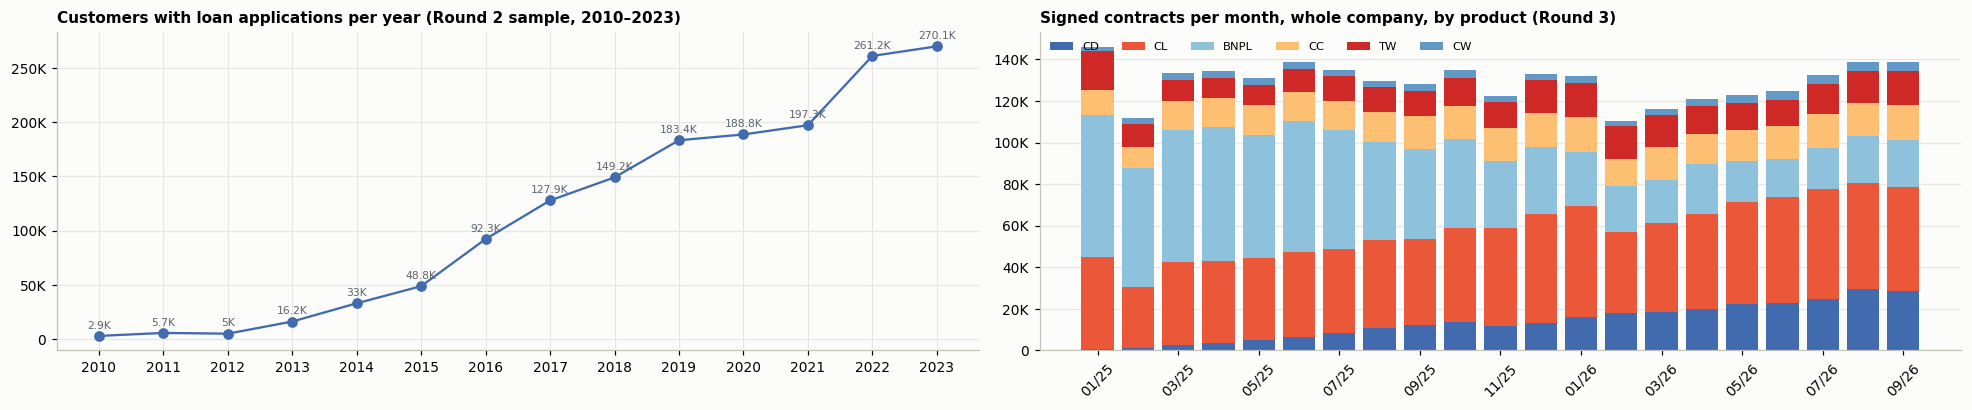

Round 2: số khách có hồ sơ tăng từ 2.9K (2010) lên 270.1K (2023), bình quân +42%/năm. Round 3: HĐ ký toàn công ty 130.9K/tháng (Q3/2025) → 136.7K/tháng (Q3/2026), +4%; cơ cấu Q3/2026: CL 38%, CD 20%, BNPL 16%, CC 12%.


In [2]:
yr = q('''SELECT year(APPLY_CONTRACT_TIME::TIMESTAMP) y, count(DISTINCT SKP_CLIENT) khach, count(*) ho_so,
                 sum(AMT_CREDIT) FILTER (WHERE NAME_CREDIT_STATUS IN ('Active','Finished','Paid off','Written off','Signed')) gia_tri
          FROM k2 GROUP BY 1 HAVING y BETWEEN 2010 AND 2023 ORDER BY 1''')
mo = q(f'''SELECT date_trunc('month', date_apply)::DATE m, coalesce(product, 'UNKNOWN') p, count(*) n FROM {rd('contract')}
           WHERE is_signed AND name_status <> 'Cancelled' GROUP BY ALL''').pivot(index='m', columns='p', values='n').fillna(0).sort_index()
mo = mo[[c for c in ['CD', 'CL', 'BNPL', 'CC', 'TW', 'CW', 'UNKNOWN'] if c in mo.columns]]
fig, ax = plt.subplots(1, 2, figsize=(18, 3.8))
ax[0].plot(yr.y, yr.khach, color=C1, marker='o'); ax[0].yaxis.set_major_formatter(mtick.FuncFormatter(human))
for x_, v_ in zip(yr.y, yr.khach): ax[0].annotate(human(v_), (x_, v_), xytext=(0, 5), textcoords='offset points', ha='center', fontsize=7, color=INK2)
ax[0].set_title('Customers with loan applications per year (Round 2 sample, 2010–2023)'); ax[0].set_xticks(yr.y)
bottom = np.zeros(len(mo)); x = np.arange(len(mo))
for i, c_ in enumerate(mo.columns):
    ax[1].bar(x, mo[c_], bottom=bottom, color=[RDYLBU[k] for k in (10, 1, 8, 3, 0, 9, 5)][i], label=c_, width=.8); bottom += mo[c_].values
ax[1].set_xticks(x[::2], [d.strftime('%m/%y') for d in mo.index][::2], rotation=45); ax[1].yaxis.set_major_formatter(mtick.FuncFormatter(human))
ax[1].legend(ncol=7, fontsize=7.5, loc='upper left'); ax[1].set_title('Signed contracts per month, whole company, by product (Round 3)'); ax[1].grid(axis='x', visible=False)
plt.tight_layout(); plt.show()
cagr = (yr.khach.iloc[-1] / yr.khach.iloc[0]) ** (1 / (len(yr) - 1)) - 1
m25, m26 = mo.loc['2025-07-01':'2025-09-01'].sum().sum() / 3, mo.loc['2026-07-01':'2026-09-01'].sum().sum() / 3
sh = mo.loc['2026-07-01':].sum() / mo.loc['2026-07-01':].sum().sum()
print(f"Round 2: số khách có hồ sơ tăng từ {human(yr.khach.iloc[0])} (2010) lên {human(yr.khach.iloc[-1])} (2023), bình quân {cagr:+.0%}/năm. "
      f"Round 3: HĐ ký toàn công ty {human(m25)}/tháng (Q3/2025) → {human(m26)}/tháng (Q3/2026), {m26 / m25 - 1:+.0%}; "
      f"cơ cấu Q3/2026: " + ', '.join(f'{k} {v:.0%}' for k, v in sh.sort_values(ascending=False).head(4).items()) + '.')

## B. Chân dung khách hàng (Round 2)
Mỗi khách một dòng. Tuổi tính đến 05/06/2025 (mốc chấm điểm Round 2); tuổi < 18 hoặc > 80 coi là bất thường và bỏ. Thu nhập chính, loại thu nhập, nghề nghiệp lấy từ hồ sơ gần nhất có giá trị (khác XNA). Tỉnh lấy từ phần cuối của địa chỉ (địa giới cũ).

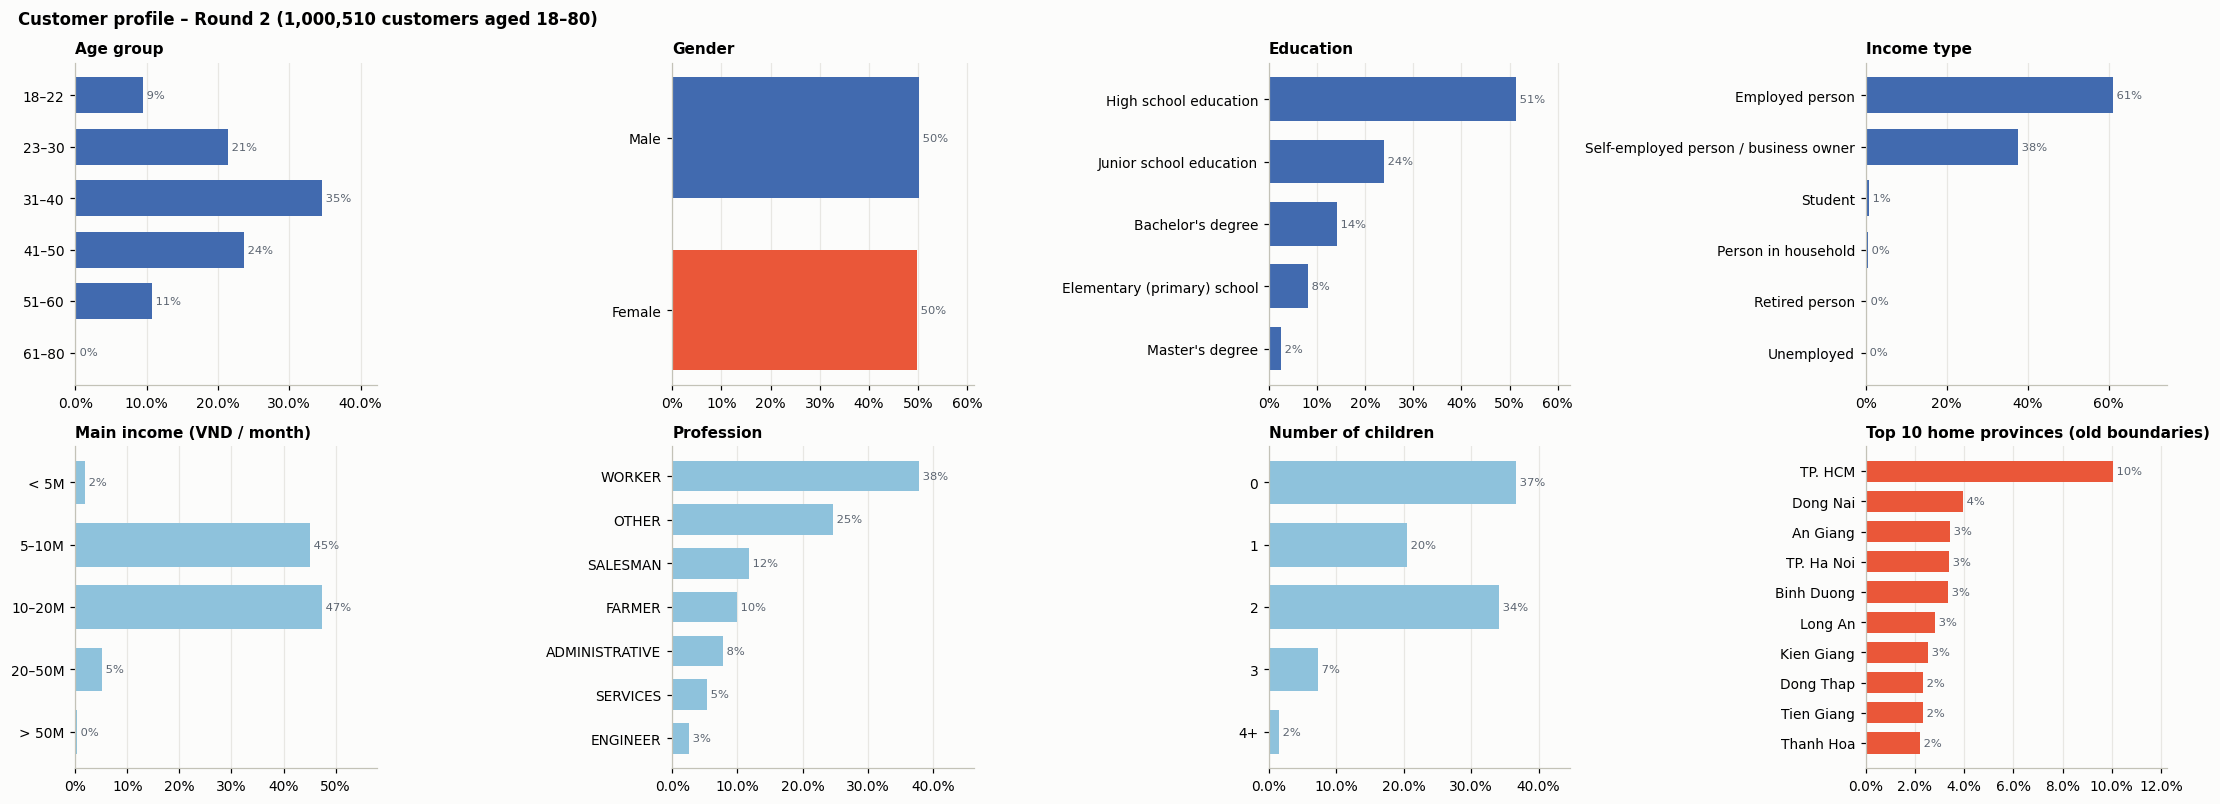

80% khách 23–50 tuổi, nhóm đông nhất 31–40 (35%); nam/nữ gần cân bằng (50%/50%). 99% có thu nhập từ làm công hoặc tự kinh doanh; 93% thu nhập 5–20 triệu/tháng. Nghề phổ biến nhất: WORKER (38%). Tỉnh có nhiều khách nhất: TP. HCM, Dong Nai, An Giang, TP. Ha Noi, Binh Duong.


In [3]:
con.sql('''CREATE TABLE prof AS
SELECT SKP_CLIENT, arg_max(NAME_INCOME_TYPE, APPLY_CONTRACT_TIME) FILTER (WHERE NAME_INCOME_TYPE <> 'XNA') inc_type,
       arg_max(CODE_PROFESSION, APPLY_CONTRACT_TIME) FILTER (WHERE CODE_PROFESSION <> 'XNA') prof,
       arg_max(AMT_INCOME_MAIN, APPLY_CONTRACT_TIME) FILTER (WHERE AMT_INCOME_MAIN > 0) inc
FROM k2 GROUP BY 1''')
cu = q('''SELECT c.*, date_diff('year', c.DATE_BIRTH::DATE, DATE '2025-06-05') age, p.inc_type, p.prof, p.inc,
                 trim(split_part(c.ADDRESS, ',', -1)) prov
          FROM cu2 c LEFT JOIN prof p USING (SKP_CLIENT)''')
cu = cu[cu.age.between(18, 80)]
age = pd.cut(cu.age, [17, 22, 30, 40, 50, 60, 80], labels=['18–22', '23–30', '31–40', '41–50', '51–60', '61–80']).value_counts(normalize=True).sort_index()
gen = cu.NAME_GENDER.replace('XNA', np.nan).dropna().value_counts(normalize=True)
edu = cu.NAME_EDUCATION_TYPE.replace('XNA', np.nan).dropna().value_counts(normalize=True).head(6)
ity = cu.inc_type.dropna().value_counts(normalize=True)
incb = pd.cut(cu.inc.dropna() / 1e6, [0, 5, 10, 20, 50, 1e9], labels=['< 5M', '5–10M', '10–20M', '20–50M', '> 50M']).value_counts(normalize=True).sort_index()
pro = cu.prof.dropna().value_counts(normalize=True).head(8)
chi = cu.CNT_CHILDREN.dropna().astype(int).clip(upper=4).map(lambda v: '4+' if v >= 4 else str(v)).value_counts(normalize=True).sort_index()
prv = cu.prov.replace('', np.nan).dropna().value_counts().head(10)
fig, ax = plt.subplots(2, 4, figsize=(20, 7.4))
barh(ax[0, 0], age.index, age.values, 'Age group', pct=True)
barh(ax[0, 1], gen.index, gen.values, 'Gender', pct=True, color=[C1, C2])
barh(ax[0, 2], edu.index, edu.values, 'Education', pct=True)
barh(ax[0, 3], ity.index, ity.values, 'Income type', pct=True)
barh(ax[1, 0], incb.index, incb.values, 'Main income (VND / month)', pct=True, color=C3)
barh(ax[1, 1], pro.index, pro.values, 'Profession', pct=True, color=C3)
barh(ax[1, 2], chi.index, chi.values, 'Number of children', pct=True, color=C3)
barh(ax[1, 3], prv.index, prv.values / len(cu), 'Top 10 home provinces (old boundaries)', pct=True, color=C2)
fig.suptitle(f'Customer profile – Round 2 ({len(cu):,} customers aged 18–80)', x=.01, ha='left', fontweight='bold')
plt.tight_layout(); plt.show()
a2350 = cu.age.between(23, 50).mean()
print(f"{a2350:.0%} khách 23–50 tuổi, nhóm đông nhất {age.idxmax()} ({age.max():.0%}); nam/nữ gần cân bằng ({gen.get('Male', 0):.0%}/{gen.get('Female', 0):.0%}). "
      f"{ity.get('Employed person', 0) + ity.get('Self-employed person / business owner', 0):.0%} có thu nhập từ làm công hoặc tự kinh doanh; "
      f"{incb.get('5–10M', 0) + incb.get('10–20M', 0):.0%} thu nhập 5–20 triệu/tháng. Nghề phổ biến nhất: {pro.idxmax()} ({pro.max():.0%}). "
      f"Tỉnh có nhiều khách nhất: {', '.join(prv.index[:5])}.")

## C. Hành vi khách hàng (Round 2)
Hợp đồng đã bỏ trùng mã hồ sơ. "Đã giải ngân" = Active, Finished, Paid off, Written off, Signed. Cờ trễ hạn kỳ 1–4 (FIRST_DUE … FOURTH_DUE) tính trên HĐ đã giải ngân.

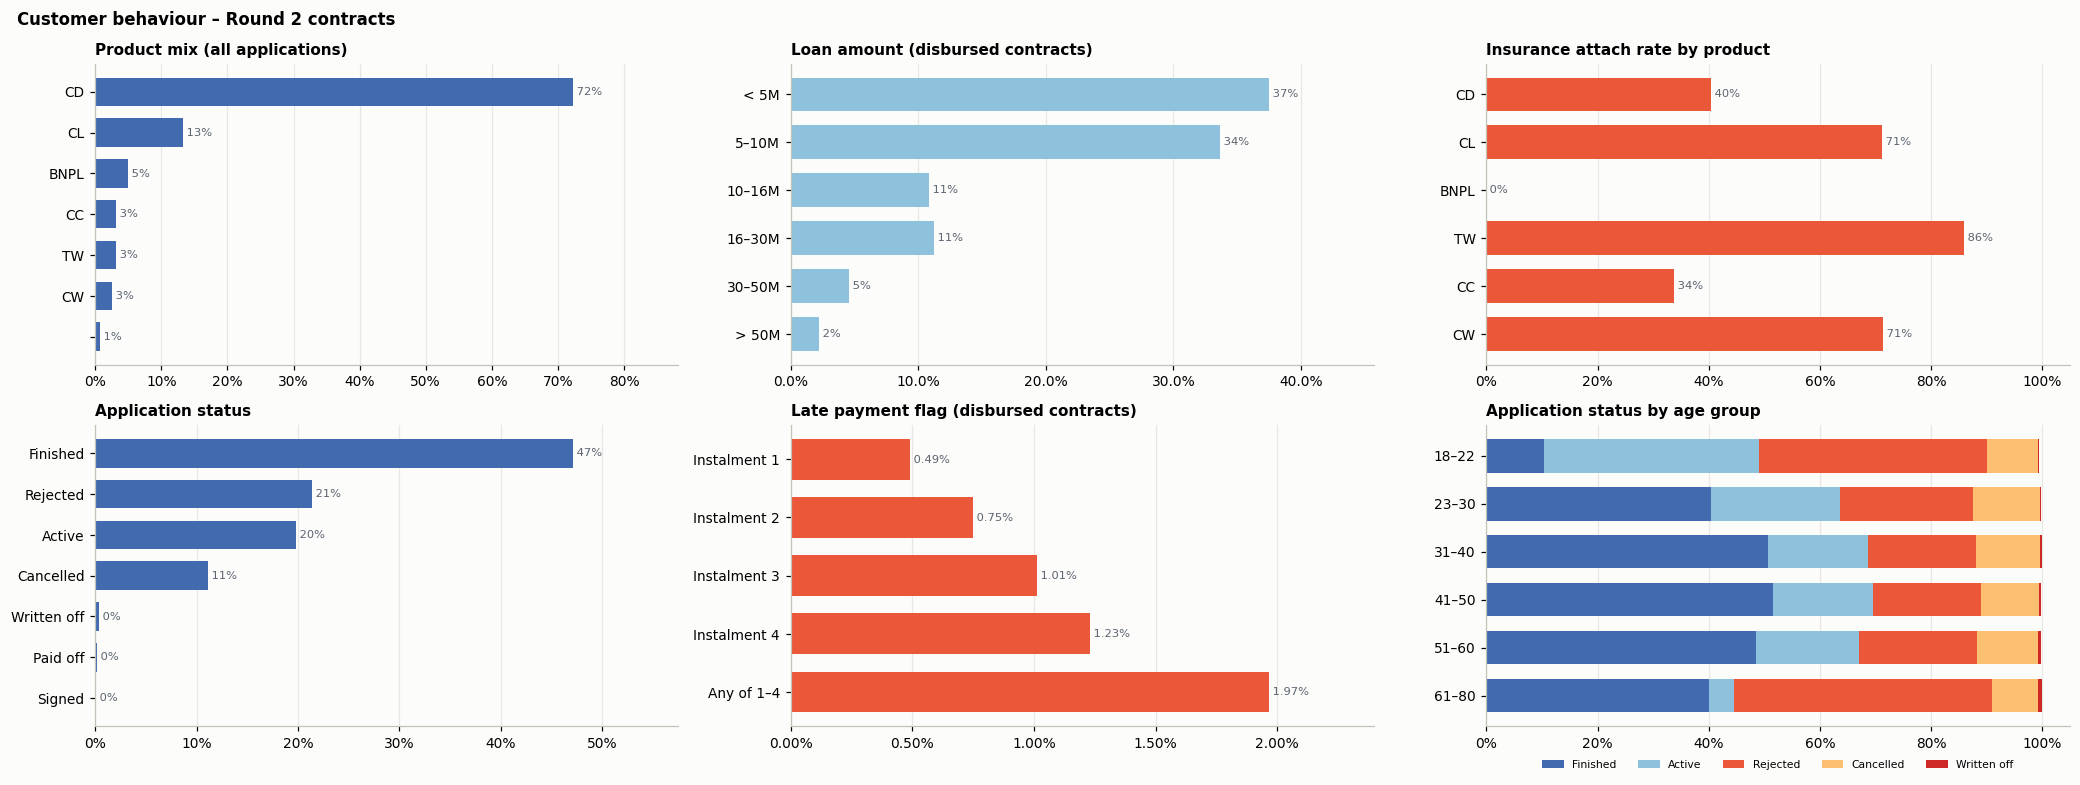

CD và CL chiếm 86% hồ sơ; 82% khoản vay dưới 16 triệu. Mua kèm bảo hiểm: CD 40%, CL 71%, BNPL 0%. 21% hồ sơ bị từ chối, 11% bị huỷ. Cờ trễ hạn bất kỳ kỳ 1–4 trên HĐ đã giải ngân: 1.97% (cờ trong dữ liệu Round 2 rất thấp so với Round 3 – xem 03_Current_Actual mục 9).


In [4]:
SIGN = "NAME_CREDIT_STATUS IN ('Active','Finished','Paid off','Written off','Signed')"
pm = q('SELECT PRODUCT p, count(*) n FROM k2 GROUP BY 1 ORDER BY 2 DESC').set_index('p').n
pm = (pm / pm.sum()).head(7)
amt = q(f'SELECT AMT_CREDIT a FROM k2 WHERE {SIGN} AND AMT_CREDIT > 0').a / 1e6
amtb = pd.cut(amt, [0, 5, 10, 16, 30, 50, 1e9], labels=['< 5M', '5–10M', '10–16M', '16–30M', '30–50M', '> 50M']).value_counts(normalize=True).sort_index()
ins = q(f"SELECT PRODUCT p, avg(FLAG_INS) r, count(*) n FROM k2 WHERE {SIGN} GROUP BY 1 HAVING count(*) > 10000 ORDER BY n DESC").set_index('p')
st = q('SELECT NAME_CREDIT_STATUS s, count(*) n FROM k2 GROUP BY 1 ORDER BY 2 DESC').set_index('s').n
st = (st / st.sum()).head(7)
due = q(f'SELECT avg(FIRST_DUE) k1, avg(SECOND_DUE) k2, avg(THIRD_DUE) k3, avg(FOURTH_DUE) k4, avg(greatest(FIRST_DUE, SECOND_DUE, THIRD_DUE, FOURTH_DUE)) any_ FROM k2 WHERE {SIGN}').iloc[0]
sa = q('''SELECT CASE WHEN a < 23 THEN '18–22' WHEN a <= 30 THEN '23–30' WHEN a <= 40 THEN '31–40' WHEN a <= 50 THEN '41–50' WHEN a <= 60 THEN '51–60' ELSE '61–80' END g,
                 NAME_CREDIT_STATUS s, count(*) n
          FROM (SELECT k.NAME_CREDIT_STATUS, date_diff('year', c.DATE_BIRTH::DATE, DATE '2025-06-05') a FROM k2 k JOIN cu2 c USING (SKP_CLIENT)) WHERE a BETWEEN 18 AND 80
          GROUP BY ALL''').pivot(index='g', columns='s', values='n').fillna(0)
sa = sa.div(sa.sum(axis=1), axis=0)[[c for c in ['Finished', 'Active', 'Rejected', 'Cancelled', 'Written off'] if c in sa.columns]]
fig, ax = plt.subplots(2, 3, figsize=(19, 7.2))
barh(ax[0, 0], pm.index, pm.values, 'Product mix (all applications)', pct=True)
barh(ax[0, 1], amtb.index, amtb.values, 'Loan amount (disbursed contracts)', pct=True, color=C3)
barh(ax[0, 2], ins.index, ins.r.values, 'Insurance attach rate by product', pct=True, color=C2)
barh(ax[1, 0], st.index, st.values, 'Application status', pct=True)
barh(ax[1, 1], ['Instalment 1', 'Instalment 2', 'Instalment 3', 'Instalment 4', 'Any of 1–4'], [due.k1, due.k2, due.k3, due.k4, due.any_],
     'Late payment flag (disbursed contracts)', pct=True, color=C2, fmt=lambda v: f'{v:.2%}')
left = np.zeros(len(sa)); y = np.arange(len(sa))
for i, c_ in enumerate(sa.columns):
    ax[1, 2].barh(y, sa[c_], left=left, color=[C1, C3, C2, C4, RDYLBU[0]][i], label=c_, height=.7); left += sa[c_].values
ax[1, 2].set_yticks(y, sa.index); ax[1, 2].invert_yaxis(); ax[1, 2].xaxis.set_major_formatter(mtick.PercentFormatter(1)); ax[1, 2].grid(axis='y', visible=False)
ax[1, 2].legend(ncol=5, fontsize=7, loc='upper center', bbox_to_anchor=(.5, -.08)); ax[1, 2].set_title('Application status by age group')
fig.suptitle('Customer behaviour – Round 2 contracts', x=.01, ha='left', fontweight='bold')
plt.tight_layout(); plt.show()
print(f"CD và CL chiếm {pm.get('CD', 0) + pm.get('CL', 0):.0%} hồ sơ; {amtb.loc[['< 5M', '5–10M', '10–16M']].sum():.0%} khoản vay dưới 16 triệu. "
      f"Mua kèm bảo hiểm: {', '.join(f'{p} {r:.0%}' for p, r in ins.r.head(3).items())}. "
      f"{st.get('Rejected', 0):.0%} hồ sơ bị từ chối, {st.get('Cancelled', 0):.0%} bị huỷ. Cờ trễ hạn bất kỳ kỳ 1–4 trên HĐ đã giải ngân: {due.any_:.2%} "
      f"(cờ trong dữ liệu Round 2 rất thấp so với Round 3 – xem 03_Current_Actual mục 9).")

## D. Hệ thống lead
- **Round 2 `LEADS`** (10/2019 – 06/2025): lead theo năm và nguồn, giờ tạo lead và giờ nhận lead trong ngày, kết quả xử lý.
- **Round 3 `leads`** (31/12/2025 – 10/2026, có trọng số `sample_weight`): lead theo tuần và nguồn; lead của shop vật lý (bỏ RTDM) so với số shop theo tỉnh.

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

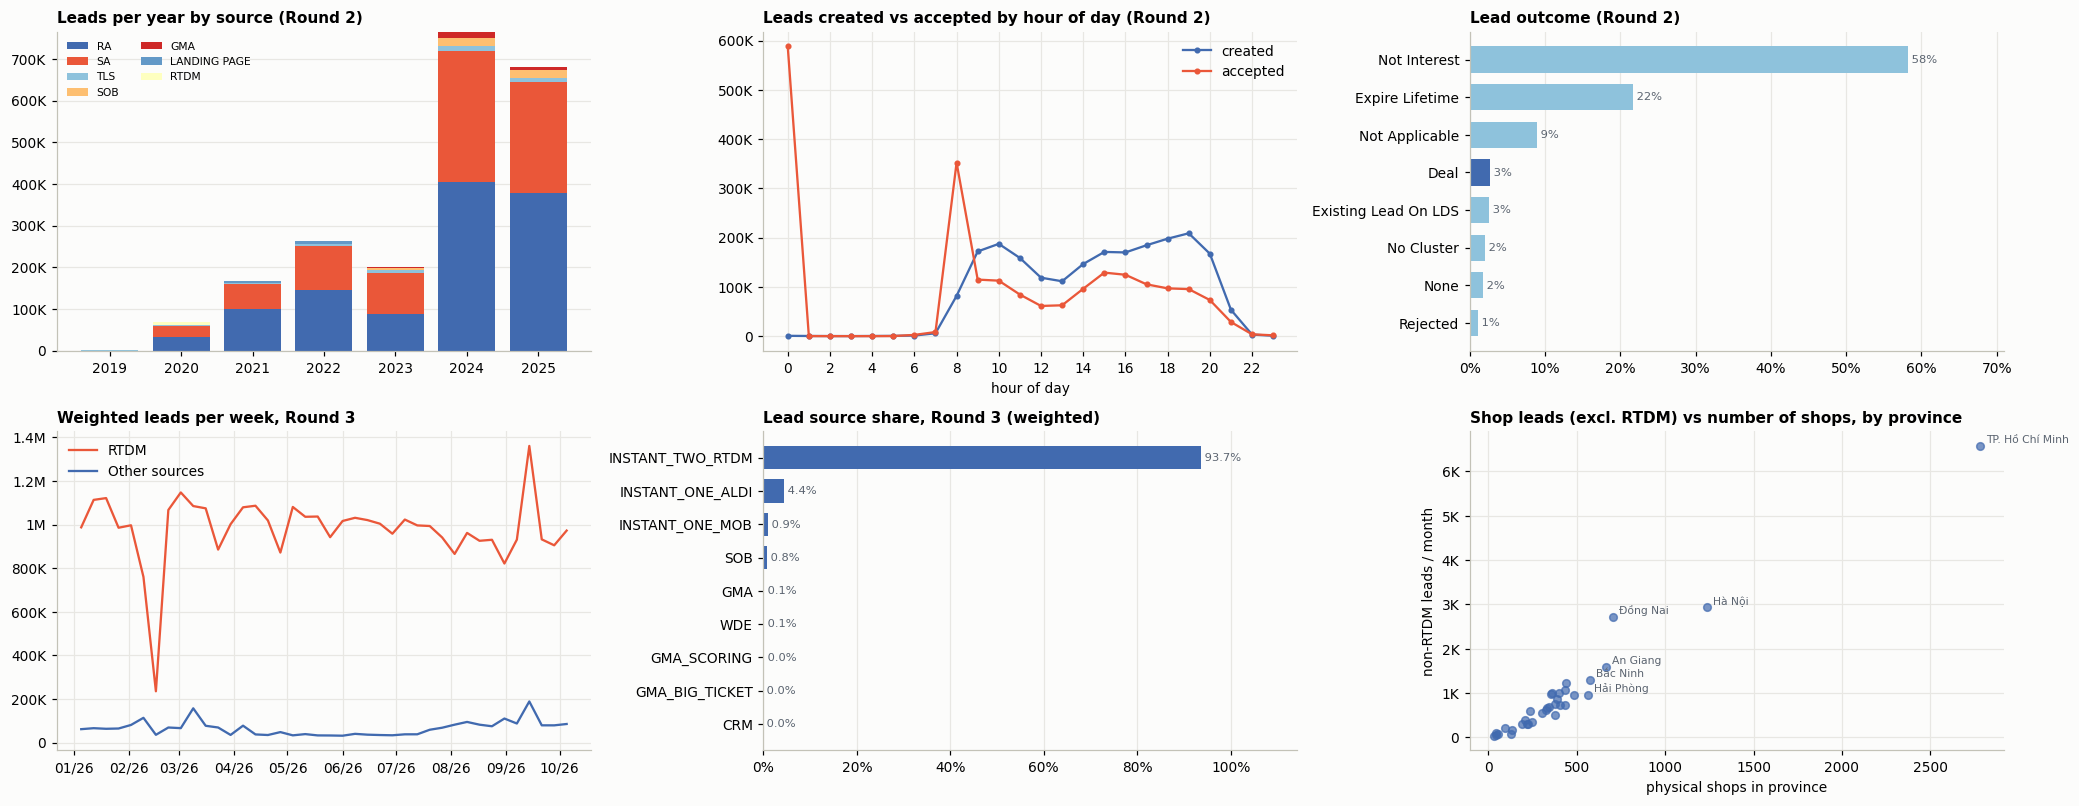

Round 2: lead tăng từ 879 (2019) lên 765.2K (2024); nguồn lớn nhất RA và SA. Lead tạo nhiều nhất lúc 19h, chỉ 0.2% tạo trong 0–6h. Kết quả: 58% không quan tâm, 2.7% DEAL. Round 3: RTDM chiếm 94% lead có trọng số. Lead (bỏ RTDM) / shop / tháng theo tỉnh dao động 0.7–3.9 (tỉnh ≥ 30 shop) → lead chưa phân bổ theo số shop.


In [5]:
l2y = q(f'''SELECT year(DTIME_CREATED::TIMESTAMP) y, LEAD_SOURCE s, count(*) n FROM {r2('LEADS')} GROUP BY ALL''').pivot(index='y', columns='s', values='n').fillna(0).sort_index()
l2y = l2y[l2y.sum().sort_values(ascending=False).index]
hr = q(f'''SELECT hour(DTIME_CREATED::TIMESTAMP) h, count(*) created, count(*) FILTER (WHERE DATE_ACCEPTED IS NOT NULL) accepted_n FROM {r2('LEADS')} GROUP BY 1''').set_index('h').sort_index()
hra = q(f'''SELECT hour(DATE_ACCEPTED::TIMESTAMP) h, count(*) accepted FROM {r2('LEADS')} WHERE DATE_ACCEPTED IS NOT NULL GROUP BY 1''').set_index('h').accepted.sort_index()
res = q(f'''SELECT coalesce(DESC_FIN_REASON, 'None') r, count(*) n FROM {r2('LEADS')} GROUP BY 1 ORDER BY 2 DESC''').set_index('r').n
res = (res / res.sum()).head(8)
l3 = q(f'''SELECT date_trunc('week', date_assigned)::DATE wk, CASE WHEN id_lead_source = 'INSTANT_TWO_RTDM' THEN 'RTDM' ELSE 'Other sources' END s, sum(sample_weight) w
           FROM {rd('leads')} WHERE date_assigned >= DATE '2026-01-05' AND date_assigned < DATE '2026-10-12' GROUP BY ALL''').pivot(index='wk', columns='s', values='w').fillna(0).sort_index()
pvl = q(f'''WITH s AS (SELECT skp_salesroom, province_std FROM {rd('salesroom')} WHERE salesroom_category <> 'Virtual'),
                l AS (SELECT s.province_std p, sum(l.sample_weight) w FROM {rd('leads')} l JOIN s USING (skp_salesroom)
                      WHERE l.id_lead_source <> 'INSTANT_TWO_RTDM' GROUP BY 1)
           SELECT s.province_std p, count(*) shops, coalesce(any_value(l.w), 0) leads FROM s LEFT JOIN l ON l.p = s.province_std GROUP BY 1''')
fig, ax = plt.subplots(2, 3, figsize=(19, 7.4))
bottom = np.zeros(len(l2y))
for i, c_ in enumerate(l2y.columns):
    ax[0, 0].bar(l2y.index, l2y[c_], bottom=bottom, color=[RDYLBU[k] for k in (10, 1, 8, 3, 0, 9, 5)][i % 7], label=c_); bottom += l2y[c_].values
ax[0, 0].yaxis.set_major_formatter(mtick.FuncFormatter(human)); ax[0, 0].legend(fontsize=7, ncol=2); ax[0, 0].set_title('Leads per year by source (Round 2)'); ax[0, 0].grid(axis='x', visible=False)
ax[0, 1].plot(hr.index, hr.created, color=C1, marker='o', ms=3, label='created'); ax[0, 1].plot(hra.index, hra.values, color=C2, marker='o', ms=3, label='accepted')
ax[0, 1].set_xticks(range(0, 24, 2)); ax[0, 1].yaxis.set_major_formatter(mtick.FuncFormatter(human)); ax[0, 1].legend(); ax[0, 1].set_xlabel('hour of day')
ax[0, 1].set_title('Leads created vs accepted by hour of day (Round 2)')
barh(ax[0, 2], res.index, res.values, 'Lead outcome (Round 2)', pct=True, color=[C3 if r != 'Deal' else C1 for r in res.index])
for i, c_ in enumerate(['RTDM', 'Other sources']):
    ax[1, 0].plot(l3.index, l3[c_], color=[C2, C1][i], label=c_)
ax[1, 0].yaxis.set_major_formatter(mtick.FuncFormatter(human)); ax[1, 0].legend(); ax[1, 0].set_title('Weighted leads per week, Round 3')
ax[1, 0].xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter('%m/%y'))
src3 = q(f'''SELECT id_lead_source s, sum(sample_weight) w FROM {rd('leads')} GROUP BY 1 ORDER BY 2 DESC''').set_index('s').w
barh(ax[1, 1], src3.index, (src3 / src3.sum()).values, 'Lead source share, Round 3 (weighted)', pct=True, fmt=lambda v: f'{v:.1%}')
ax[1, 2].scatter(pvl.shops, pvl.leads / 9.5, s=25, color=C1, alpha=.7)
for _, r_ in pvl.nlargest(6, 'shops').iterrows(): ax[1, 2].annotate(r_.p, (r_.shops, r_.leads / 9.5), xytext=(4, 2), textcoords='offset points', fontsize=7, color=INK2)
ax[1, 2].set_xlabel('physical shops in province'); ax[1, 2].set_ylabel('non-RTDM leads / month'); ax[1, 2].yaxis.set_major_formatter(mtick.FuncFormatter(human))
ax[1, 2].set_title('Shop leads (excl. RTDM) vs number of shops, by province')
plt.tight_layout(); plt.show()
pk = hr.created.idxmax(); low = hr.created.loc[0:6].sum() / hr.created.sum()
pv_ = pvl.assign(lps=pvl.leads / pvl.shops / 9.5)
print(f"Round 2: lead tăng từ {human(l2y.sum(axis=1).iloc[0])} ({l2y.index[0]}) lên {human(l2y.sum(axis=1).max())} ({l2y.sum(axis=1).idxmax()}); "
      f"nguồn lớn nhất {l2y.columns[0]} và {l2y.columns[1]}. Lead tạo nhiều nhất lúc {pk}h, chỉ {low:.1%} tạo trong 0–6h. "
      f"Kết quả: {res.get('Not Interest', 0):.0%} không quan tâm, {res.get('Deal', 0):.1%} DEAL. "
      f"Round 3: RTDM chiếm {src3.get('INSTANT_TWO_RTDM', 0) / src3.sum():.0%} lead có trọng số. Lead (bỏ RTDM) / shop / tháng theo tỉnh dao động "
      f"{pv_[pv_.shops >= 30].lps.min():.1f}–{pv_[pv_.shops >= 30].lps.max():.1f} (tỉnh ≥ 30 shop) → lead chưa phân bổ theo số shop.")

## E. Đội ngũ SA
- **Số SA đang được gán** mỗi tháng (bảng phân công `emp_2_salesroom`, role = SA).
- **Số shop mỗi SA phụ trách** (tháng 09/2026): SA chuyên trách (≤ 3 shop) hay lưu động.
- **Tải việc:** lead (có trọng số, **bỏ RTDM** để không lẫn hiệu ứng loại lead) mỗi SA mỗi tháng theo mã SA trong `leads`, và tỷ lệ lead ra HĐ ký theo mức tải (lead giao trước 09/2026).

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

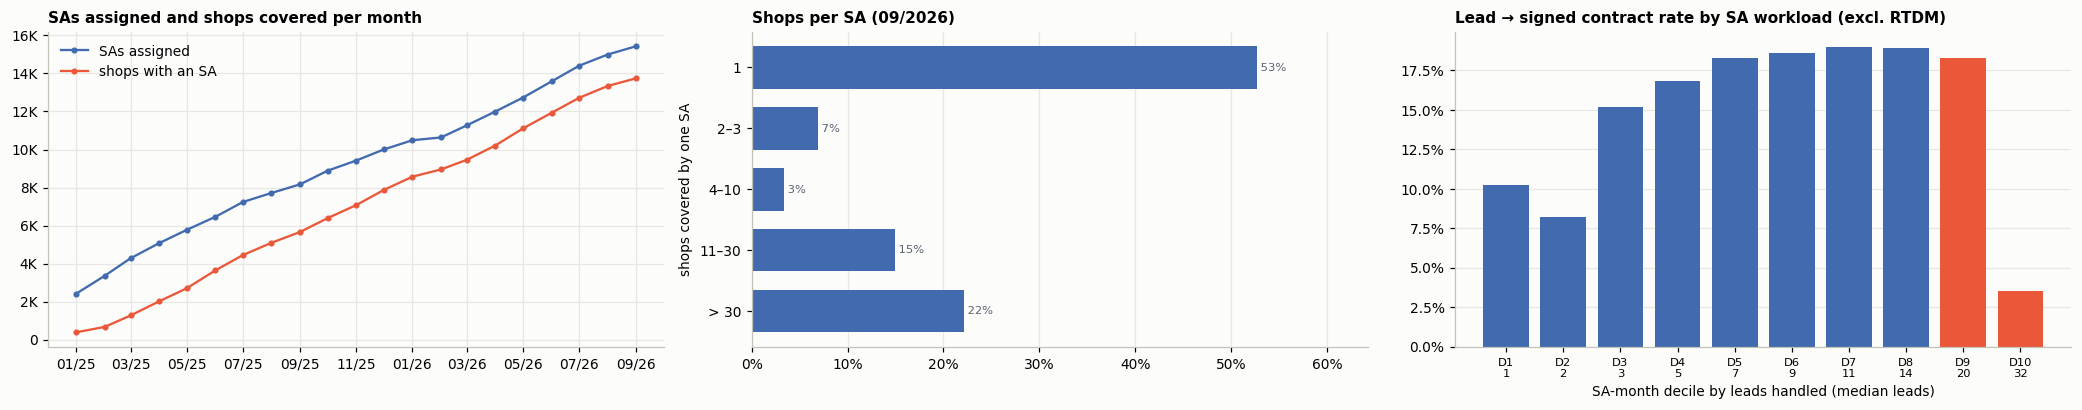

Số SA được gán tăng từ 2,420 (01/2025) lên 15,433 (09/2026), phủ 13,746 shop. Tháng 09/2026: 60% SA phụ trách ≤ 3 shop, 22% SA phụ trách > 30 shop (tài khoản lưu động / giám sát). Tải việc: nhóm 10% SA-tháng nhiều lead nhất xử lý trung vị 32 lead/tháng, tỷ lệ ra HĐ 3.5% so với 18.3% ở nhóm giữa (D5) → có dấu hiệu quá tải.


In [6]:
sam = q(f'''WITH m AS (SELECT unnest(generate_series(DATE '2025-01-01', DATE '2026-09-01', INTERVAL 1 MONTH))::DATE m),
                 e AS (SELECT skp_employee, skp_salesroom, dtime_valid_from f, CASE WHEN year(dtime_valid_to) >= 2999 THEN NULL ELSE dtime_valid_to END t
                       FROM {rd('emp_2_salesroom')} WHERE role = 'SA')
            SELECT m.m, count(DISTINCT e.skp_employee) sa, count(DISTINCT e.skp_salesroom) shops FROM m JOIN e
              ON e.f < m.m + INTERVAL 1 MONTH AND (e.t IS NULL OR e.t >= m.m) GROUP BY 1 ORDER BY 1''')
sps = q(f'''WITH e AS (SELECT skp_employee, skp_salesroom FROM {rd('emp_2_salesroom')} WHERE role = 'SA' AND dtime_valid_from < DATE '2026-10-01'
                       AND (dtime_valid_to IS NULL OR year(dtime_valid_to) >= 2999 OR dtime_valid_to >= DATE '2026-09-01'))
            SELECT skp_employee, count(DISTINCT skp_salesroom) n FROM e GROUP BY 1''')
spb = pd.cut(sps.n, [0, 1, 3, 10, 30, 1e6], labels=['1', '2–3', '4–10', '11–30', '> 30']).value_counts().sort_index()
ld = q(f'''SELECT code_sa, date_trunc('month', date_assigned)::DATE m, sum(sample_weight) w, sum(sample_weight) FILTER (WHERE converted_sign) cv
           FROM {rd('leads')} WHERE code_sa IS NOT NULL AND date_assigned < DATE '2026-09-01' AND id_lead_source <> 'INSTANT_TWO_RTDM' GROUP BY ALL''')
ld['band'] = pd.qcut(ld.w.rank(method='first'), 10, labels=[f'D{i}' for i in range(1, 11)])
lb = ld.groupby('band', observed=True).agg(lead_tb=('w', 'median'), w=('w', 'sum'), cv=('cv', 'sum')); lb['conv'] = lb.cv / lb.w
fig, ax = plt.subplots(1, 3, figsize=(19, 3.8))
ax[0].plot(sam.m, sam.sa, color=C1, marker='o', ms=3, label='SAs assigned'); ax[0].plot(sam.m, sam.shops, color=C2, marker='o', ms=3, label='shops with an SA')
ax[0].yaxis.set_major_formatter(mtick.FuncFormatter(human)); ax[0].legend(); ax[0].xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter('%m/%y'))
ax[0].set_title('SAs assigned and shops covered per month')
barh(ax[1], spb.index, (spb / spb.sum()).values, 'Shops per SA (09/2026)', pct=True)
ax[1].set_ylabel('shops covered by one SA')
ax[2].bar(range(10), lb.conv, color=[C1 if i < 8 else C2 for i in range(10)])
ax[2].set_xticks(range(10), [f'{b}\n{human(v)}' for b, v in zip(lb.index, lb.lead_tb)], fontsize=7.5)
ax[2].yaxis.set_major_formatter(mtick.PercentFormatter(1)); ax[2].set_xlabel('SA-month decile by leads handled (median leads)')
ax[2].set_title('Lead → signed contract rate by SA workload (excl. RTDM)'); ax[2].grid(axis='x', visible=False)
plt.tight_layout(); plt.show()
ded = (sps.n <= 3).mean()
print(f"Số SA được gán tăng từ {sam.sa.iloc[0]:,} (01/2025) lên {sam.sa.iloc[-1]:,} (09/2026), phủ {sam.shops.iloc[-1]:,} shop. "
      f"Tháng 09/2026: {ded:.0%} SA phụ trách ≤ 3 shop, {(sps.n > 30).mean():.0%} SA phụ trách > 30 shop (tài khoản lưu động / giám sát). "
      f"Tải việc: nhóm 10% SA-tháng nhiều lead nhất xử lý trung vị {human(lb.lead_tb.iloc[-1])} lead/tháng, tỷ lệ ra HĐ {lb.conv.iloc[-1]:.1%} "
      f"so với {lb.conv.iloc[4]:.1%} ở nhóm giữa (D5) → {'có dấu hiệu quá tải' if lb.conv.iloc[-1] < .7 * lb.conv.iloc[4] else 'chưa thấy dấu hiệu quá tải rõ'}.")

## Kết luận bối cảnh
Các con số kết luận được in ngay dưới mỗi biểu đồ. Bối cảnh này dẫn sang câu hỏi của đề:
- **Thị trường** còn tăng và khác nhau rõ giữa các tỉnh → trần thị trường phải tính theo địa bàn (`05` Bước 6).
- **Khách hàng** chủ yếu thu nhập trung bình, vay khoản nhỏ qua CD → shop là cửa ngõ thu hút khách mới, giá trị đến sau qua CL (`03` mục 5.2).
- **Lead** phần lớn là RTDM và không phân theo số shop → đòn bẩy "phân lead chiến dịch về shop" (`05` Bước 5).
- **SA** phần lớn phụ trách nhiều shop → số SA được gán không đo được năng lực thật; tác động của SA chỉ thấy ở shop Aldi (`05` Bước 5).